In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression
plt.rcParams['figure.figsize'] = (10, 4)

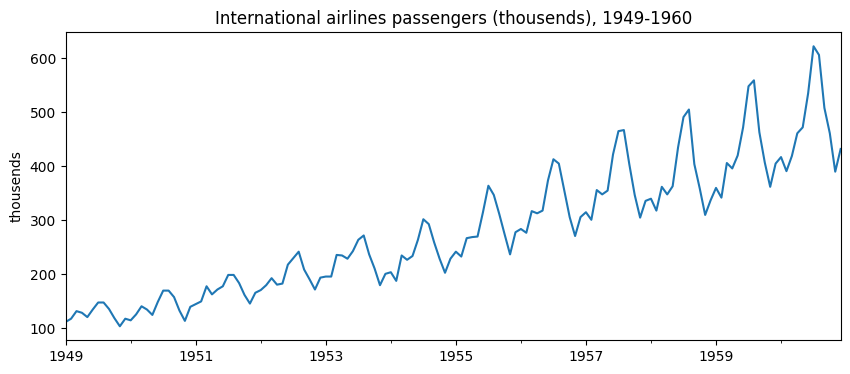

In [2]:
import seaborn as sns
flights = sns.load_dataset('flights')
y = pd.Series(flights['passengers'].values,
              index=pd.date_range('1949-01-01', periods = 144, freq = 'MS'), name='passengers')
assert len(y) == 144 and y.sum() == 40363
y.plot(title = 'International airlines passengers (thousends), 1949-1960'); plt.ylabel('thousends');plt.show()

In [3]:
train, test = y[:'1958'], y['1959':]
H = len(test)                                # forecast horizon: 24 months
print(f'train: {len(train)} months ({train.index[0]:%b %Y} - {train.index[-1]:%b %Y})')
print(f'test : {len(test)} months ({test.index[0]:%b %Y} - {test.index[-1]:%b %Y})')
print(f'max passengers in train: {train.max()}   max in test: {test.max()}')

def rmse(f, a): return float(np.sqrt(np.mean((np.asarray(f, float) - np.asarray(a, float)) ** 2)))
def mape(f, a): return float(100 * np.mean(np.abs((np.asarray(f, float) - np.asarray(a, float)) / np.asarray(a, float))))
results = {}

train: 120 months (Jan 1949 - Dec 1958)
test : 24 months (Jan 1959 - Dec 1960)
max passengers in train: 505   max in test: 622


In [4]:
snaive = np.tile(train.values[-12:], 2)
results['Seasonal naive'] = (rmse(snaive, test), mape(snaive, test))
print('Seasonal naive RMSE %.1f MAPE %.1f%%' % results['Seasonal naive'])

Seasonal naive RMSE 77.0 MAPE 15.5%


In [5]:
def make_windows(s, p):
    s = np.asarray(s, float)
    X = np.array([s[i - p:i] for i in range(p, len(s))])
    return X, s[p:]

def recursive_forecast(model, history, p, h):
    hist = list(np.asarray(history, float))
    out = []
    for _ in range(h):
        nxt = float(model.predict(np.array(hist[-p:]).reshape(1, -1))[0])
        out.append(nxt); hist.append(nxt)
    return np.array(out)

X_demo, t_demo = make_windows(np.arange(1, 8), 3)
print(X_demo, t_demo)

[[1. 2. 3.]
 [2. 3. 4.]
 [3. 4. 5.]
 [4. 5. 6.]] [4. 5. 6. 7.]


MLP on log levels   RMSE 113.9   MAPE 20.0%
highest scaled input seen in training: 2.04; scaled log of Jul 1960: 2.57


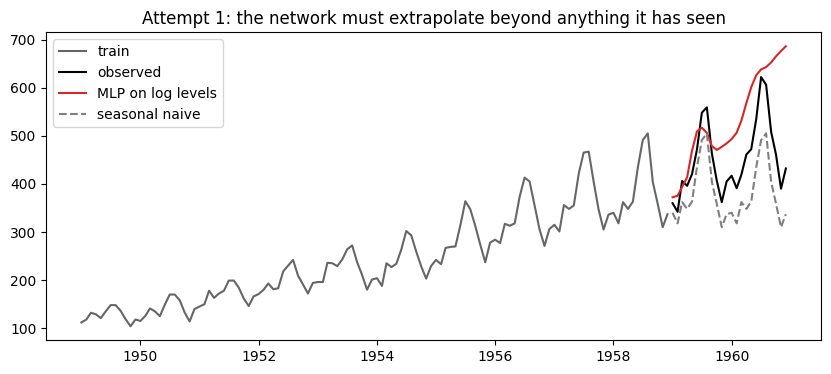

In [7]:
p = 12
L = np.log(y.values)                                                      # log levels, all 144 months[cite: 16]
Ltr = L[:len(train)]
m, s = Ltr.mean(), Ltr.std()                                              # training constants only[cite: 16]
Xtr, ttr = make_windows((Ltr - m) / s, p)

mlp_levels = MLPRegressor(hidden_layer_sizes=(32,), activation='relu', alpha=1e-3,
                          max_iter=5000, random_state=0)
mlp_levels.fit(Xtr, ttr)

f_scaled = recursive_forecast(mlp_levels, (Ltr - m) / s, p, H)
f_levels = np.exp(f_scaled * s + m)
results['MLP on log levels'] = (rmse(f_levels, test), mape(f_levels, test))
print('MLP on log levels   RMSE %.1f   MAPE %.1f%%' % results['MLP on log levels'])
print(f'highest scaled input seen in training: {Xtr.max():.2f}; scaled log of Jul 1960: {(L[-6] - m) / s:.2f}')

plt.plot(train.index, train, color='0.4', label='train')
plt.plot(test.index, test, 'k', label='observed')
plt.plot(test.index, f_levels, 'C3', label='MLP on log levels')
plt.plot(test.index, snaive, 'C7--', label='seasonal naive')
plt.legend(); plt.title('Attempt 1: the network must extrapolate beyond anything it has seen'); plt.show()

In [9]:
def z_of(Lser):
    Lser = np.asarray(Lser, float)
    return Lser[13:] - Lser[12:-1] - Lser[1:-12] + Lser[:-13]    # (1 - B)(1 - B^12) log y, defined from t = 13

def undo(z_future, L_hist):
    """Rebuild log levels month by month from forecast z and the observed history."""
    Lh = list(L_hist)
    for zt in z_future:
        Lh.append(zt + Lh[-1] + Lh[-12] - Lh[-13])
    return np.array(Lh[len(L_hist):])

p = 13
ztr = z_of(Ltr)                                                  # 107 values, training months only
mz, sz = ztr.mean(), ztr.std()
Xz, tz = make_windows((ztr - mz) / sz, p)
print('training windows:', Xz.shape)

def mlp_forecast(seed):
    net = MLPRegressor(hidden_layer_sizes=(32,), activation='relu', alpha=1e-3, max_iter=5000, random_state=seed)
    net.fit(Xz, tz)
    zf = recursive_forecast(net, (ztr - mz) / sz, p, H) * sz + mz
    return np.exp(undo(zf, Ltr))

f_mlp = mlp_forecast(0)
results['MLP transform'] = (rmse(f_mlp, test), mape(f_mlp, test))
print('MLP transform RMSE %.1f MAPE %.1f%%' % results['MLP transform'])

training windows: (94, 13)
MLP transform RMSE 80.1 MAPE 15.1%


Linear AR(13)   RMSE 67.6   MAPE 13.2%


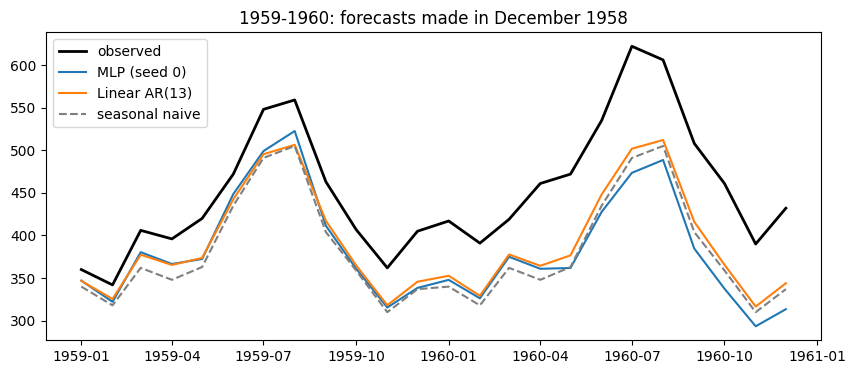

In [11]:
lin = LinearRegression().fit(Xz, tz)
zf_lin = recursive_forecast(lin, (ztr - mz) / sz, p, H) * sz + mz
f_lin = np.exp(undo(zf_lin, Ltr))
results['Linear AR(13) on Class 7 transform'] = (rmse(f_lin, test), mape(f_lin, test))
print('Linear AR(13)   RMSE %.1f   MAPE %.1f%%' % results['Linear AR(13) on Class 7 transform'])

plt.plot(test.index, test, 'k', lw=2, label='observed')
plt.plot(test.index, f_mlp, 'C0', label="MLP (seed 0)")
plt.plot(test.index, f_lin, 'C1', label='Linear AR(13)')
plt.plot(test.index, snaive, 'C7--', label='seasonal naive')
plt.legend(); plt.title('1959-1960: forecasts made in December 1958'); plt.show()

RMSE over 10 seeds: min 31.4  median 64.1  max 102.3
MAPE over 10 seeds: min 5.7%  median 12.1%  max 19.9%
MLP ensemble   RMSE 67.5   MAPE 13.0%


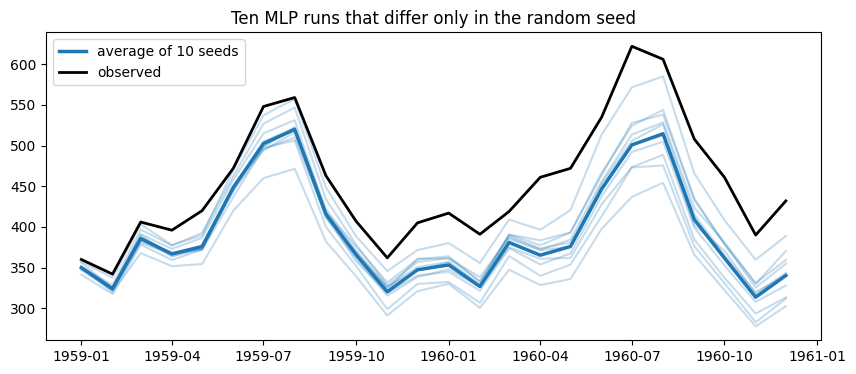

In [12]:
runs = np.array([mlp_forecast(seed) for seed in range(10)])
r_rmse = [rmse(f, test) for f in runs]; r_mape = [mape(f, test) for f in runs]
print('RMSE over 10 seeds: min %.1f  median %.1f  max %.1f' % (min(r_rmse), np.median(r_rmse), max(r_rmse)))
print('MAPE over 10 seeds: min %.1f%%  median %.1f%%  max %.1f%%' % (min(r_mape), np.median(r_mape), max(r_mape)))
f_ens = np.exp(np.log(runs).mean(0))                      # average in log scale
results['MLP, average of 10 seeds'] = (rmse(f_ens, test), mape(f_ens, test))
print('MLP ensemble   RMSE %.1f   MAPE %.1f%%' % results['MLP, average of 10 seeds'])

plt.plot(test.index, runs.T, color='C0', alpha=.25)
plt.plot(test.index, f_ens, 'C0', lw=2.5, label='average of 10 seeds')
plt.plot(test.index, test, 'k', lw=2, label='observed')
plt.legend(); plt.title('Ten MLP runs that differ only in the random seed'); plt.show()

In [14]:
table = pd.DataFrame(results, index = ['RMSE', 'MAPE (%)']).T.round(1)
table

,RMSE,MAPE (%)
Seasonal naive,77.0,15.5
MLP on log levels,113.9,20.0
MLP transform,80.1,15.1
MLP on transform,80.1,15.1
Linear AR(13) on Class 7 transform,67.6,13.2
"MLP, average of 10 seeds",67.5,13.0
